# House Prices — XGBoost trên 79 và 82 đặc trưng

Đo tác động của việc thêm ba cột tổng hợp với cùng cấu hình XGBoost và cùng 5 fold của thí nghiệm gốc.

## Tham số cố định

In [1]:
EXPERIMENT_NAME = "15-11-2026_XGBoost_82_phuc"
RANDOM_STATE = 42
N_SPLITS = 5
MODEL_PARAMS = {
    "n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
    "random_state": RANDOM_STATE, "n_jobs": 2,
}

## Import và kiểm tra kernel

In [2]:
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

try:
    import xgboost
except ModuleNotFoundError as error:
    if error.name != "xgboost":
        raise
    raise ModuleNotFoundError(
        "Kernel chua co XGBoost. Chay %pip install xgboost-cpu roi Restart Kernel."
    ) from error

from src.model import make_xgboost
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor

## Dữ liệu và tạo đặc trưng

- `TotalSF` cộng diện tích tầng hầm, tầng 1 và tầng 2.
- `TotalBath` cộng phòng tắm đầy đủ ở phần trên mặt đất và tầng hầm. Mỗi nửa phòng tắm tính 0,5.
- `AgeAtSale` lấy năm bán trừ năm xây.

Các phép tính dùng dữ liệu của từng căn nhà. Pipeline điền thiếu, chuẩn hóa và mã hóa được fit trên phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

formulas = {
    "TotalSF": "TotalBsmtSF + 1stFlrSF + 2ndFlrSF",
    "TotalBath": "FullBath + BsmtFullBath + 0.5 * (HalfBath + BsmtHalfBath)",
    "AgeAtSale": "YrSold - YearBuilt",
}
X_extra = X.assign(
    TotalSF=X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"],
    TotalBath=X["FullBath"] + X["BsmtFullBath"] + 0.5 * (X["HalfBath"] + X["BsmtHalfBath"]),
    AgeAtSale=X["YrSold"] - X["YearBuilt"],
)
assert X_extra.shape[1] == 82
display(X_extra[list(formulas)].describe().round(2))

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y, "fold": 0})
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold
baseline_dir = (project / "experiments" / "14-11-2026_6model_79_phuc"
                / "outputs" / "20261114_224507_500186")
baseline = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline[[ID, "fold"]])
np.testing.assert_allclose(y, baseline["ln_SalePrice"])

,TotalSF,TotalBath,AgeAtSale
count,1460.00,1460.00,1460.00
mean,2567.05,2.21,36.55
std,821.71,0.79,30.25
min,334.00,1.00,0.00
25%,2009.50,2.00,8.00
50%,2474.00,2.00,35.00
75%,3004.00,2.50,54.00
max,11752.00,6.00,136.00


## Huấn luyện và so sánh

In [4]:
metric_rows = []
warning_rows = []
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
for name, features in {"79": X, "82": X_extra}.items():
    pipeline = make_pipeline(make_preprocessor(features), make_xgboost(**MODEL_PARAMS))
    scores = []
    started = perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = clone(pipeline).fit(features.iloc[fit_idx], y.iloc[fit_idx])
            predicted = fitted.predict(features.iloc[valid_idx])
        predictions.loc[valid_idx, f"xgboost_{name}"] = predicted
        scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))
        for item in caught:
            warning_rows.append({"features": name, "fold": fold,
                                 "category": item.category.__name__, "message": str(item.message)})
    metric_rows.append({
        "model": "XGBoost", "features": int(name),
        **dict(zip(fold_columns, scores)),
        "rmse_log_mean": np.mean(scores), "rmse_log_std": np.std(scores, ddof=1),
        "elapsed_seconds": perf_counter() - started,
    })

results = pd.DataFrame(metric_rows).set_index("features")
assert predictions[["xgboost_79", "xgboost_82"]].notna().all().all()
comparison = results.loc[[79, 82], fold_columns].T
comparison.columns = ["rmse_79", "rmse_82"]
comparison["delta_82_minus_79"] = comparison["rmse_82"] - comparison["rmse_79"]
display(results.round(5))
display(comparison.round(5))

,model,fold1,fold2,fold3,fold4,fold5,rmse_log_mean,rmse_log_std,elapsed_seconds
features,,,,,,,,,
79,XGBoost,0.13278,0.11839,0.16912,0.13413,0.11311,0.13351,0.02187,1.40399
82,XGBoost,0.13851,0.11829,0.16862,0.12793,0.11756,0.13418,0.02105,1.42091


,rmse_79,rmse_82,delta_82_minus_79
fold1,0.13278,0.13851,0.00573
fold2,0.11839,0.11829,-0.00010
fold3,0.16912,0.16862,-0.00050
fold4,0.13413,0.12793,-0.00619
fold5,0.11311,0.11756,0.00445


## Biểu đồ và nhận xét

Delta RMSE log (82 - 79): +0.00068. RMSE lower on 3/5 folds.


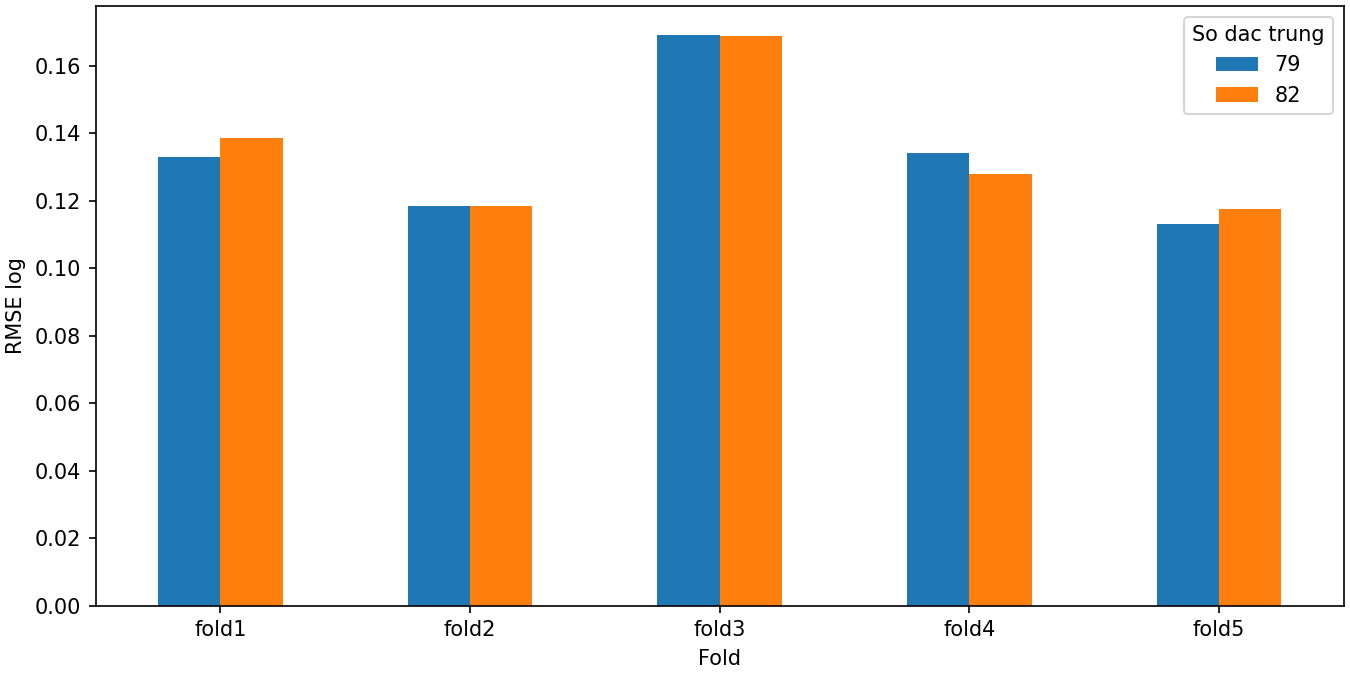

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
comparison[["rmse_79", "rmse_82"]].rename(columns={
    "rmse_79": "79", "rmse_82": "82",
}).plot.bar(ax=ax, rot=0)
ax.set(ylabel="RMSE log", xlabel="Fold")
ax.legend(title="So dac trung")
plt.show()
delta = results.loc[82, "rmse_log_mean"] - results.loc[79, "rmse_log_mean"]
wins = int((comparison["delta_82_minus_79"] < 0).sum())
print(f"Delta RMSE log (82 - 79): {delta:+.5f}. RMSE lower on {wins}/5 folds.")

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv")
comparison.to_csv(run_dir / "comparison_79_vs_82.csv", index_label="fold")
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
pd.DataFrame(warning_rows, columns=["features", "fold", "category", "message"]).to_csv(
    run_dir / "validation_warnings.csv", index=False
)
config = {
    "dataset": "data/raw/train.csv", "target_transform": "natural log",
    "baseline": str(baseline_dir.relative_to(project)), "feature_formulas": formulas,
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "model_params": MODEL_PARAMS, "xgboost_version": xgboost.__version__,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "xgboost_79_vs_82.png", dpi=150)
print(run_dir.relative_to(project))

experiments\15-11-2026_XGBoost_82_phuc\outputs\20261115_092626_226656
